# Next-game model: win probability from this game's deck, the record so far, and skill

This notebook predicts **the next game** of a Premier Draft run, rather than the run as a whole. Three
reasons it has to be done one game at a time:

* **Opponents depend on the record.** If Arena pairs players by record, a 5-1 deck faces tougher decks than a
  0-0 deck, so the same 40 cards are worth a different win probability at different points in the run.
* **The deck can change between games.** About one run in five rebuilds part-way through. Each game here uses
  the deck that was registered *for that game*.
* **Some context exists only per game**: play/draw, mulligans, both players' current rank.

The model is the game-level model from `scripts/deck_synergy.py`, plus the record before the game and the
player's experience bucket:

P(win game) = σ( b + f(deck) + record<sub>W-L</sub> + rank + opp rank + skill + experience + play/draw + mulligans )

f(deck) is either linear (card power) or a factorization machine (card power + pair synergy).

Sections:
1. How this differs from `deckstrength.ipynb`
2. Data: one row per game, its own deck
3. Rebuilding the record before each game
4. Fitting the models
5. What the record does at a fixed deck
6. League (rank), skill and experience
7. Card power with and without the record, and pair synergy
8. Predicting the next game
9. Takeaways

Code: `src/openlane/deckstrength.py` (`record_before`, `record_onehot`, `experience`, `covariates`) and
`src/openlane/synergy.py` (the model). Needs `data/parquet/MSH.PremierDraft{,.game}.parquet`. The fits run on
CPU in a few minutes.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import torch
from scipy.stats import spearmanr
from sklearn.metrics import log_loss, roc_auc_score

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from openlane.data import RANK_ORDER
from openlane.deckstrength import (MAX_LOSSES, MAX_WINS, N_GAMES_BUCKETS, N_RANKS, aligned, covariates,
                                   experience, flag, game_split, load_drafts, record_before, record_onehot)
from openlane.games import game_path
from openlane.synergy import fit

SET, EVENT = "MSH", "PremierDraft"
torch.set_num_threads(6)

# reference categorical palette, fixed order (same as the other notebooks)
BLUE, ORANGE, AQUA, YELLOW, MAGENTA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"
GRAY, INK, MUTED, SURFACE, GRID = "#a3a29c", "#0b0b0b", "#52514e", "#fcfcfb", "#e6e5e0"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "lines.linewidth": 2, "font.size": 10, "legend.frameon": False,
})
pl.Config.set_tbl_rows(25); pl.Config.set_fmt_str_lengths(40); pl.Config.set_tbl_width_chars(140)

polars.config.Config

## 1. How this differs from `deckstrength.ipynb`

| | deck strength (`deckstrength.ipynb`) | next-game model (this notebook) |
|---|---|---|
| one example is | a whole run (draft) | one game |
| target | the run's W-L, as p<sup>W</sup>(1-p)<sup>L</sup> | did this game end in a win |
| deck | the build played most, one per run | the build registered for this game |
| context | the drafter's rank | record before the game, current rank and opponent rank, play/draw, mulligans, skill and experience buckets |
| answers | "how good is this draft?" | "what are my odds in the next game, at 4-1, on the draw?" |

Both use the same time-based split. A game takes its draft's split (train / val / test = first 70% / next 15% /
last 15% of drafts by draft time), so every game of a test draft is a test game.

## 2. Data: one row per game, with its own deck

In [2]:
t0 = time.time()
d = load_drafts(SET, EVENT)
names = np.array(d.names)
games = pl.read_parquet(game_path(SET, EVENT))
split = game_split(d, games["draft_id"])
games, split = games.filter(pl.Series(split >= 0)), split[split >= 0]

wins_before, losses_before, known = record_before(games)
X_all = aligned(games, "deck_", d.names).astype(np.float32)
y_all = flag(games["won"]).astype(np.int8)
print(f"{games.height:,} games from {games['draft_id'].n_unique():,} drafts  [{time.time() - t0:.0f}s]")

builds = games.group_by("draft_id").agg(pl.col("build_index").n_unique().alias("builds"))
print(f"runs that rebuilt the deck at least once: {(builds['builds'] > 1).mean():.1%}")

377,376 games from 67,785 drafts  [3s]
runs that rebuilt the deck at least once: 19.0%


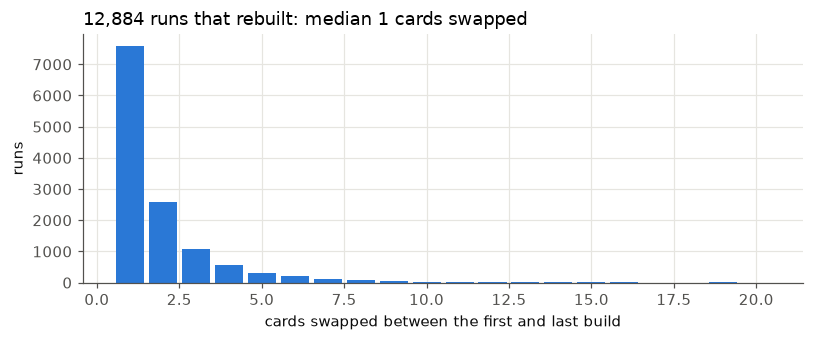

In [3]:
# How big are the rebuilds? Cards changed between a run's first and last build (half the L1 distance).
first_last = (games.with_row_index("i").sort("draft_id", "match_number")
              .group_by("draft_id").agg(pl.col("i").first().alias("a"), pl.col("i").last().alias("b"),
                                        pl.col("build_index").n_unique().alias("n")).filter(pl.col("n") > 1))
changed = np.abs(X_all[first_last["a"].to_numpy()] - X_all[first_last["b"].to_numpy()]).sum(1) / 2
fig, ax = plt.subplots(figsize=(7.5, 3.2))
ax.hist(changed, bins=np.arange(0.5, 21.5), color=BLUE, rwidth=0.85)
ax.set_xlabel("cards swapped between the first and last build"); ax.set_ylabel("runs")
ax.set_title(f"{len(changed):,} runs that rebuilt: median {np.median(changed):.0f} cards swapped", loc="left")
plt.tight_layout(); plt.show()

## 3. Rebuilding the record before each game

Game data has no "record so far" column, so it is rebuilt from the run's own games. Games are ordered by
`match_number`, and the record before a game counts the wins and losses in the run's earlier games.

17Lands does not have every game of every run, so the record is counted from **the games we have**. For a game
with earlier games missing, the record undercounts. That affects the 16% of games printed below; in most of them
only one earlier game is missing. The draft table's final W-L can't fill the gaps: it is a snapshot, and for many
runs the game file has *more* games than it records.

games whose earlier games are all present: 83.9%  (316,617 of 377,376); all games are used
train / val / test games: 266,251 / 56,679 / 54,446


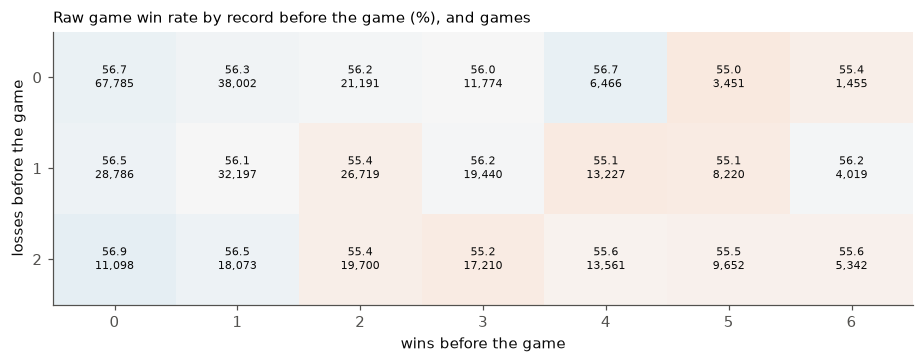

In [4]:
print(f"games whose earlier games are all present: {known.mean():.1%}  ({known.sum():,} of {len(known):,}); "
      "all games are used")
gm, X, y, sp = games, X_all, y_all, split
wb, lb = wins_before, losses_before
print(f"train / val / test games: {np.sum(sp == 0):,} / {np.sum(sp == 1):,} / {np.sum(sp == 2):,}")

def record_grid(values, wins, losses, how="mean"):
    out = np.full((MAX_LOSSES, MAX_WINS), np.nan)
    n = np.zeros((MAX_LOSSES, MAX_WINS), dtype=int)
    for li in range(MAX_LOSSES):
        for wi in range(MAX_WINS):
            m = (wins == wi) & (losses == li)
            n[li, wi] = m.sum()
            if m.sum():
                out[li, wi] = values[m].mean() if how == "mean" else values[m][0]
    return out, n

def heat(ax, grid, n, title, fmt, cmap, vmin, vmax, center=None):
    im = ax.imshow(grid, cmap=cmap, vmin=vmin, vmax=vmax, aspect="auto")
    for (li, wi), v in np.ndenumerate(grid):
        if np.isfinite(v):
            ax.text(wi, li, fmt(v) + (f"\n{n[li, wi]:,}" if n is not None else ""), ha="center", va="center",
                    fontsize=7.5, color=INK)
    ax.set_xticks(range(MAX_WINS)); ax.set_yticks(range(MAX_LOSSES)); ax.grid(False)
    ax.set_xlabel("wins before the game"); ax.set_ylabel("losses before the game")
    ax.set_title(title, loc="left", fontsize=10)
    return im

raw, n_rec = record_grid(y.astype(float), wb, lb)
fig, ax = plt.subplots(figsize=(8.5, 3.4))
heat(ax, raw * 100, n_rec, "Raw game win rate by record before the game (%), and games", lambda v: f"{v:.1f}",
     "RdBu", 46, 66)
plt.tight_layout(); plt.show()

The raw win rate is almost **flat** across the record, between 55% and 57% everywhere. That is surprising. Only
strong decks and strong players get to 5-0 or 6-0, so if opponents were the same at every record, the win rate
would climb with wins. A flat line means opponents get tougher as the wins pile up, consistent with Arena pairing
players by record. Section 5 separates the two effects.

## 4. Fitting the models

Every model is a logistic regression in PyTorch (`synergy.fit`): Adam, L2 on the card weights, early stopping on
validation games. The regularisation is the value `deck_synergy.py` chose for MSH. The blocks of inputs:

* **deck**: card counts of this game's deck, lands included
* **game**: play/draw, user rank and opponent rank (one-hot, with "unknown"). All known before the game starts.
* **mulligans**: the user's mulligans minus the opponent's. Only known once the game has started, so the
  pre-game models leave it out; `deck_synergy.py` includes it, so its reproduction does too.
* **skill**: `user_game_win_rate_bucket`, the user's 17Lands game win rate. It is *leaky*: it is computed over all
  of the user's games in the data, including this one and later ones. Shown with and without.
* **experience**: `user_n_games_bucket` (1 / 5 / 10 / 50 / 100+ games logged). Much less leaky.
* **record**: one-hot of the record before the game, 0-0 to 6-2 (21 states)

In [5]:
cov_full = covariates(gm).astype(np.float32)   # [play, mull, skill, skill_known, rank (7), opp rank (7)]
MULL, SKILL = [1], [2, 3]
game_cols = [i for i in range(cov_full.shape[1]) if i not in MULL + SKILL]
blocks = {"game": cov_full[:, game_cols], "mulligans": cov_full[:, MULL], "skill": cov_full[:, SKILL],
          "experience": experience(gm), "record": record_onehot(wb, lb)}

def context(*parts):
    """Concatenate blocks and remember where each one sits."""
    cols, at = [], {}
    for p in parts:
        at[p] = slice(sum(c.shape[1] for c in cols), sum(c.shape[1] for c in cols) + blocks[p].shape[1])
        cols.append(blocks[p])
    return np.hstack(cols), at

none = np.zeros_like(X[:, :1])
specs = [  # name, deck input, context blocks, FM rank k, l2 on card weights, l2 on pair vectors
    ("deck_synergy.py (+ mulligans)",   True,  ("game", "mulligans", "skill"), 0, 1e-4, 0),
    ("context only, no deck",           False, ("game", "skill", "experience", "record"), 0, 0, 0),
    ("deck + game + skill",             True,  ("game", "skill"), 0, 1e-4, 0),
    ("+ experience",                    True,  ("game", "skill", "experience"), 0, 1e-4, 0),
    ("+ experience + record",           True,  ("game", "skill", "experience", "record"), 0, 1e-4, 0),
    ("+ experience + record, no skill", True,  ("game", "experience", "record"), 0, 1e-4, 0),
    ("+ experience + record + synergy", True,  ("game", "skill", "experience", "record"), 4, 1e-5, 1e-3),
]
te_idx = np.flatnonzero(sp == 2)
models, preds, layout, rows = {}, {}, {}, []
for name, use_deck, parts, k, l2w, l2v in specs:
    t1 = time.time()
    C_in, at = context(*parts)
    m, val, predict = fit(X if use_deck else none, C_in, y, sp, k, l2w, l2v, log=lambda s: None)
    p = predict(te_idx)
    models[name], preds[name], layout[name] = m, p, at
    rows.append({"model": name, "val log loss": round(val, 5), "test log loss": round(log_loss(y[te_idx], p), 5),
                 "test AUC": round(roc_auc_score(y[te_idx], p), 4), "fit (s)": round(time.time() - t1)})
    print(f"{name:34s} test log loss {rows[-1]['test log loss']:.5f}  AUC {rows[-1]['test AUC']:.4f}  "
          f"[{rows[-1]['fit (s)']}s]", flush=True)
base_ll = log_loss(y[te_idx], np.full(len(te_idx), y[sp == 0].mean()))
res = pl.DataFrame(rows).with_columns((pl.col("test log loss") - base_ll).round(5).alias("vs constant"))
print(f"constant (train win rate {y[sp == 0].mean():.3f}): test log loss {base_ll:.5f}")
res

deck_synergy.py (+ mulligans)      test log loss 0.65716  AUC 0.6344  [5s]


context only, no deck              test log loss 0.67081  AUC 0.5981  [2s]


deck + game + skill                test log loss 0.66791  AUC 0.6082  [4s]


+ experience                       test log loss 0.66786  AUC 0.6083  [3s]


+ experience + record              test log loss 0.66642  AUC 0.6121  [4s]


+ experience + record, no skill    test log loss 0.67773  AUC 0.5765  [1s]


+ experience + record + synergy    test log loss 0.66701  AUC 0.6109  [5s]


constant (train win rate 0.564): test log loss 0.68703


model,val log loss,test log loss,test AUC,fit (s),vs constant
str,f64,f64,f64,i64,f64
"""deck_synergy.py (+ mulligans)""",0.6622,0.65716,0.6344,5,-0.02987
"""context only, no deck""",0.67267,0.67081,0.5981,2,-0.01622
"""deck + game + skill""",0.67087,0.66791,0.6082,4,-0.01912
"""+ experience""",0.6708,0.66786,0.6083,3,-0.01917
"""+ experience + record""",0.66941,0.66642,0.6121,4,-0.02061
"""+ experience + record, no skill""",0.67957,0.67773,0.5765,1,-0.0093
"""+ experience + record + synergy""",0.66996,0.66701,0.6109,5,-0.02002


How to read the table (log loss is per test game, lower is better):

* **Mulligans are in-game information, and they are worth a lot.** `deck_synergy.py`'s model, which includes them,
  scores 0.6572. The same inputs without mulligans score 0.6679. A pre-game prediction can't know them, so every
  other row, and `predict_next` below, leaves them out.
* **The record helps on every metric**: -0.0014 log loss and +0.004 AUC over `+ experience`. For scale, the whole
  deck is worth 0.0044 (`context only, no deck` vs `+ experience + record`), so the record is worth about a third
  as much as knowing the 40 cards.
* **The skill bucket is the biggest single input**: dropping it costs 0.011, about 2.5× what the deck is worth.
  Part of that is leakage (it includes this game's result), so treat the rows with it as optimistic.
* **Experience adds almost nothing** once the skill bucket is in (0.66786 vs 0.66791). The two overlap.
* **Synergy doesn't help**: the FM is 0.0006 worse than the linear model on test games.

## 5. What the record does at a fixed deck

Left: the raw win rate from section 3. Right: the record coefficients of `+ experience + record`, relative to
0-0, converted to percentage points at the average win rate. This is the change in win probability for **the same
deck, player and context**, moving from 0-0 to that record.

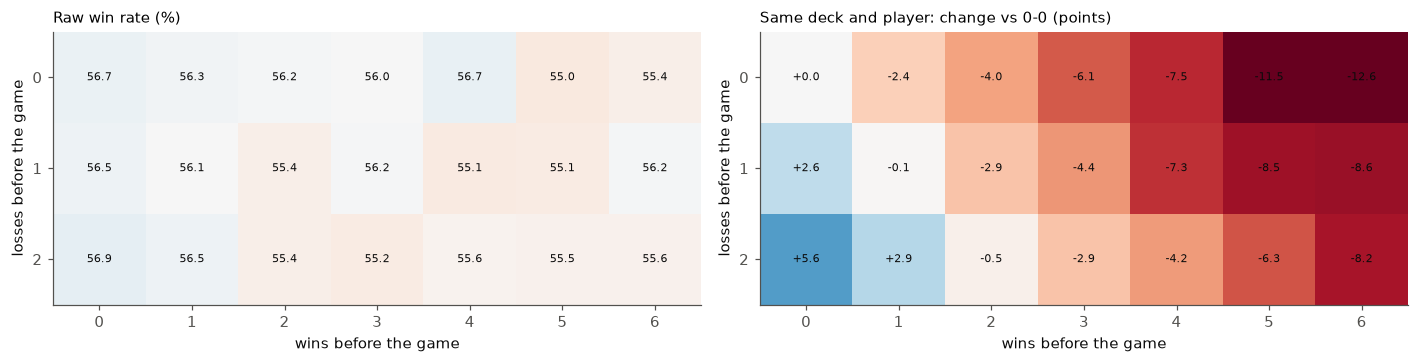

change vs 0-0, percentage points (rows = losses, cols = wins):
[[  0.   -2.4  -4.   -6.1  -7.5 -11.5 -12.6]
 [  2.6  -0.1  -2.9  -4.4  -7.3  -8.5  -8.6]
 [  5.6   2.9  -0.5  -2.9  -4.2  -6.3  -8.2]]


mean deck score (log-odds, vs decks at 0-0) of the decks that reach each record:
shape: (7, 4)
┌──────┬──────────┬──────────┬──────────┐
│ wins ┆ 0 losses ┆ 1 losses ┆ 2 losses │
│ ---  ┆ ---      ┆ ---      ┆ ---      │
│ i64  ┆ f64      ┆ f64      ┆ f64      │
╞══════╪══════════╪══════════╪══════════╡
│ 0    ┆ 0.0      ┆ -0.032   ┆ -0.058   │
│ 1    ┆ 0.025    ┆ -0.006   ┆ -0.035   │
│ 2    ┆ 0.049    ┆ 0.018    ┆ -0.01    │
│ 3    ┆ 0.073    ┆ 0.041    ┆ 0.016    │
│ 4    ┆ 0.098    ┆ 0.063    ┆ 0.04     │
│ 5    ┆ 0.119    ┆ 0.083    ┆ 0.06     │
│ 6    ┆ 0.139    ┆ 0.101    ┆ 0.074    │
└──────┴──────────┴──────────┴──────────┘


In [6]:
MAIN = "+ experience + record"
def block_weights(name, part):
    return models[name].cov.weight[0, layout[name][part]].detach().numpy()

rec_w = block_weights(MAIN, "record")
rec_w = rec_w - rec_w[0]
p0 = y[sp == 0].mean()
lo0 = np.log(p0 / (1 - p0))
rec_pts = (1 / (1 + np.exp(-(lo0 + rec_w))) - p0) * 100
adj = rec_pts.reshape(MAX_LOSSES, MAX_WINS)
adj[n_rec < 300] = np.nan  # too few games to read

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.4))
heat(a1, raw * 100, None, "Raw win rate (%)", lambda v: f"{v:.1f}", "RdBu", 46, 66)
heat(a2, adj, None, "Same deck and player: change vs 0-0 (points)", lambda v: f"{v:+.1f}", "RdBu", -10, 10)
plt.tight_layout(); plt.show()
print("change vs 0-0, percentage points (rows = losses, cols = wins):")
print(np.round(adj, 1))

# deck strength by record: mean of the model's deck score for the decks that reach each record
deck_score = (X @ models[MAIN].w.detach().numpy())
ds_grid, _ = record_grid(deck_score, wb, lb)
print("mean deck score (log-odds, vs decks at 0-0) of the decks that reach each record:")
print(pl.DataFrame({f"{li} losses": np.round(ds_grid[li] - ds_grid[0, 0], 3) for li in range(MAX_LOSSES)})
      .with_columns(pl.Series("wins", range(MAX_WINS))).select("wins", *[f"{li} losses" for li in range(MAX_LOSSES)]))

At a fixed deck and player, **each win before the game costs about 2 points of win probability, and each loss gives
about 2.5-3 back**. At 6-0 the same deck wins 12.6 points less often than at 0-0. At 0-2 it wins 5.6 points more often.

The table underneath shows the other half of the story. The decks that reach 6-0 score 0.14 log-odds better than the
average deck at 0-0, about +3.5 points. Better decks reaching high records and tougher opponents at high records
cancel out, which is why the raw win rate is flat.

The record term cannot fully separate matchmaking from what the record says about the player. Being 5-0 also
means the deck and player are probably better than the model's inputs show, and that pushes the 5-0 coefficient
*up*. So the true matchmaking penalty is, if anything, larger than shown. Momentum or tilt would push the other way
(winners win more), and the data show the opposite.

For a run-level rating, this effect is already baked into the W-L target. For **the next game**, it has to be an input.

## 6. League (rank), skill and experience

The other context coefficients of the same model. Ranks are relative to Bronze, experience relative to "1 game",
and the skill bucket is per 10 points of the user's overall game win rate.

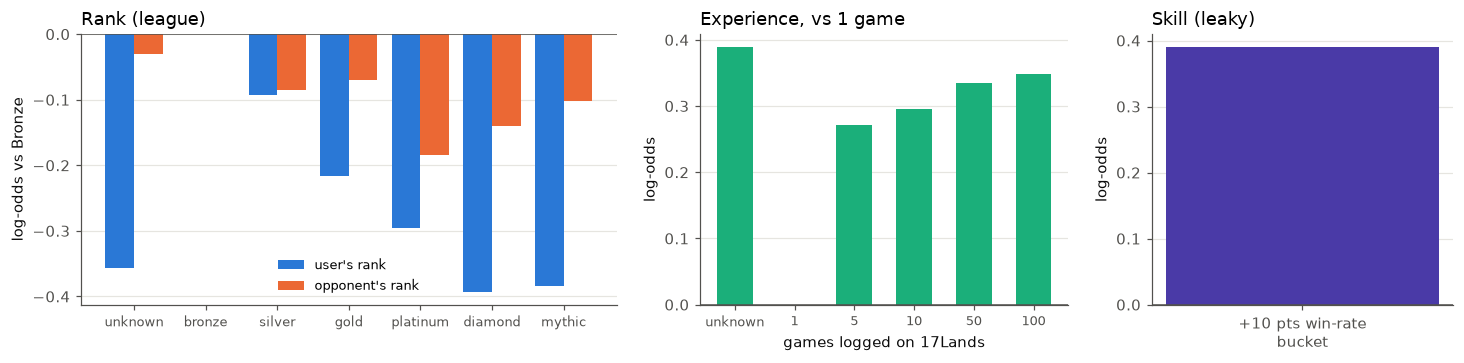

on the play vs the draw: +0.211 log-odds; each extra mulligan vs the opponent (deck_synergy.py model): -0.625


In [7]:
gw = block_weights(MAIN, "game")
mull_w = block_weights("deck_synergy.py (+ mulligans)", "mulligans")[0]
rank_labels = ["unknown"] + list(RANK_ORDER)
user_rank, opp_rank = gw[1:1 + N_RANKS], gw[1 + N_RANKS:1 + 2 * N_RANKS]
exp_w = block_weights(MAIN, "experience")
skill_w = block_weights(MAIN, "skill")

fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.4), gridspec_kw={"width_ratios": [1.6, 1.1, 0.9]})
xx = np.arange(N_RANKS)
axes[0].bar(xx - 0.2, user_rank - user_rank[1], width=0.4, color=BLUE, label="user's rank")
axes[0].bar(xx + 0.2, opp_rank - opp_rank[1], width=0.4, color=ORANGE, label="opponent's rank")
axes[0].set_xticks(xx, rank_labels, fontsize=8.5); axes[0].axhline(0, color=MUTED, lw=1)
axes[0].set_ylabel("log-odds vs Bronze"); axes[0].legend(fontsize=8.5); axes[0].grid(axis="x", visible=False)
axes[0].set_title("Rank (league)", loc="left")
axes[1].bar(range(len(exp_w)), exp_w - exp_w[1], color=AQUA, width=0.6)
axes[1].set_xticks(range(len(exp_w)), ["unknown", *N_GAMES_BUCKETS], fontsize=8.5)
axes[1].axhline(0, color=MUTED, lw=1); axes[1].grid(axis="x", visible=False)
axes[1].set_xlabel("games logged on 17Lands"); axes[1].set_title("Experience, vs 1 game", loc="left")
axes[2].bar([0], [skill_w[0] * 0.1], color=VIOLET, width=0.5)
axes[2].set_xticks([0], ["+10 pts win-rate\nbucket"]); axes[2].axhline(0, color=MUTED, lw=1)
axes[2].grid(axis="x", visible=False); axes[2].set_title("Skill (leaky)", loc="left")
for a in axes:
    a.set_ylabel("log-odds") if a is not axes[0] else None
plt.tight_layout(); plt.show()
print(f"on the play vs the draw: {gw[0]:+.3f} log-odds; each extra mulligan vs the opponent "
      f"(deck_synergy.py model): {mull_w:+.3f}")

* **Play/draw**: being on the play is worth +0.21 log-odds, about 5 points.
* **League**: the user's own rank is the bigger term. Higher rank means tougher opponents, from -0.09 at Silver to
  -0.39 at Diamond relative to Bronze. Arena pairs within rank, so the user's rank mostly says who they face. The
  opponent's rank adds a smaller penalty on top (about -0.03 to -0.18). "Unknown" rank is missing data, not a league.
* **Skill**: +0.39 log-odds per 10 points of the user's 17Lands win-rate bucket, the strongest context term. It is
  leaky, though. For live use, swap in the player's own win rate from *earlier* events only.
* **Experience**: players with more logged games win more, but the skill bucket already captures it (section 4).

## 7. Card power with and without the record, and pair synergy

Adding the record changes the card weights a little: part of what looked like card power was the record
(stronger decks get further, where opponents are tougher, so without the record their cards are
*under*-credited). Cards in at least 2,000 training games:

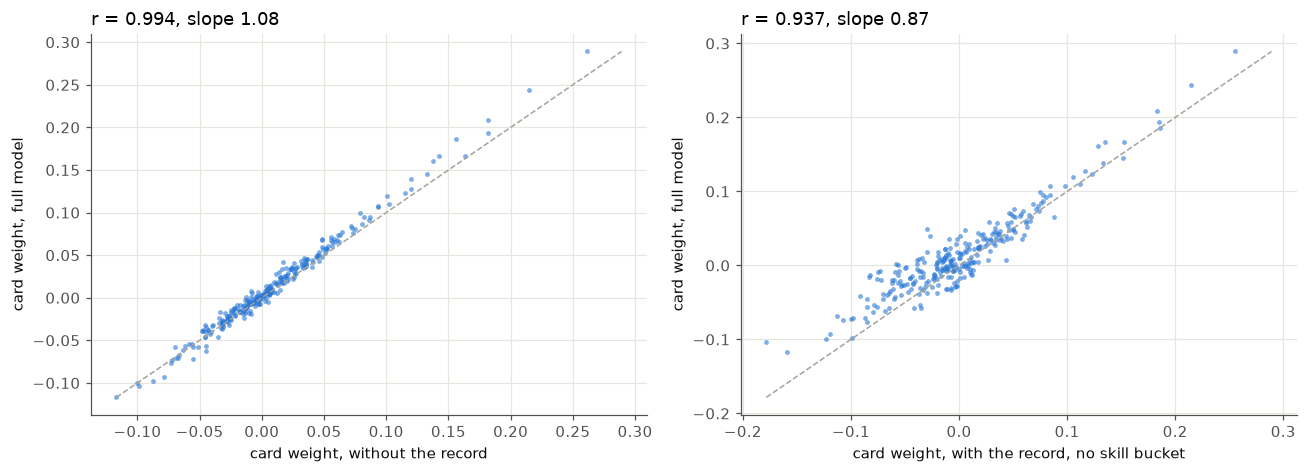

Highest card power (log-odds per copy, full model)


card,weight (full),weight (no record),weight (no skill),train games
str,f32,f32,f32,i64
"""Captain Marvel, Earth's Protector""",0.289,0.261,0.255,8091
"""The Super Hero Civil War""",0.244,0.215,0.214,17374
"""Doctor Doom""",0.209,0.182,0.183,6857
"""Leader, Super-Genius""",0.194,0.182,0.185,17830
"""Jennifer Walters""",0.186,0.156,0.186,7614
"""M.O.D.O.K.""",0.167,0.142,0.153,6611
"""The Coming of Galactus""",0.166,0.163,0.135,6196
"""Agent Phil Coulson""",0.161,0.137,0.129,15802
"""Avengers: Under Siege""",0.145,0.133,0.152,10676


In [8]:
tr = sp == 0
n_games_card = (X[tr] > 0).sum(0)
common = n_games_card >= 2000
w_no = models["+ experience"].w.detach().numpy()
w_rec = models[MAIN].w.detach().numpy()
w_noskill = models["+ experience + record, no skill"].w.detach().numpy()
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4.4))
for ax, other, lab in ((a1, w_no, "without the record"), (a2, w_noskill, "with the record, no skill bucket")):
    ax.scatter(other[common], w_rec[common], s=10, color=BLUE, alpha=0.6, lw=0)
    lim = [min(other[common].min(), w_rec[common].min()), max(other[common].max(), w_rec[common].max())]
    ax.plot(lim, lim, color=GRAY, ls="--", lw=1)
    slope = np.polyfit(other[common], w_rec[common], 1)[0]
    ax.set_xlabel(f"card weight, {lab}"); ax.set_ylabel("card weight, full model")
    ax.set_title(f"r = {np.corrcoef(other[common], w_rec[common])[0, 1]:.3f}, slope {slope:.2f}", loc="left")
plt.tight_layout(); plt.show()
power = (pl.DataFrame({"card": names, "weight (full)": w_rec, "weight (no record)": w_no,
                       "weight (no skill)": w_noskill, "train games": n_games_card})
         .filter(pl.col("train games") >= 2000).with_columns(pl.col(pl.Float32).round(3)))
print("Highest card power (log-odds per copy, full model)")
display(power.sort("weight (full)", descending=True).head(10))

**Adding the record barely moves the card weights** (r = 0.994). It stretches them by about 8%: without the record,
cards in strong decks were partly blamed for the tougher opponents those decks get paired against. Dropping the skill
bucket moves them more (r = 0.94). Without it, cards that good players take get some credit for the player.

**Pair synergy.** The FM adds a vector v per card, and a pair's synergy is ⟨v<sub>i</sub>, v<sub>j</sub>⟩ for
every pair of cards in the deck. Pairs that appear together in at least 2,000 training games:

In [9]:
SYN = "+ experience + record + synergy"
V = models[SYN].v.detach().numpy()
P = (X[tr] > 0).astype(np.float32)
co = P.T @ P
iu = np.triu_indices(len(names), 1)
ok = co[iu] >= 2000
pairs = (pl.DataFrame({"card a": names[iu[0]][ok], "card b": names[iu[1]][ok], "synergy": (V @ V.T)[iu][ok],
                       "games together": co[iu][ok].astype(int)})
         .with_columns(pl.col("synergy").round(4)))
print(f"sd of pair synergy {pairs['synergy'].std():.4f} log-odds; sd of card power {w_rec[common].std():.3f}")
print("Strongest positive pairs"); display(pairs.sort("synergy", descending=True).head(8))
print("Strongest negative pairs"); display(pairs.sort("synergy").head(8))

sd of pair synergy 0.0014 log-odds; sd of card power 0.054
Strongest positive pairs


card a,card b,synergy,games together
str,str,f32,i64
"""Madame Hydra""","""Yellowjacket, Heartless Marauder""",0.0104,3543
"""Baron Strucker, HYDRA Overlord""","""Yellowjacket, Heartless Marauder""",0.0092,5714
"""Klaw, Sonic Subjugator""","""Yellowjacket, Heartless Marauder""",0.0085,6248
"""Killmonger, Scourge of Wakanda""","""Yellowjacket, Heartless Marauder""",0.008,3404
"""Bullseye, Death Dealer""","""Killmonger, Scourge of Wakanda""",0.0071,2311
"""HYDRA Assault Robot""","""Yellowjacket, Heartless Marauder""",0.0071,2762
"""Baron Strucker, HYDRA Overlord""","""Killmonger, Scourge of Wakanda""",0.0068,3795
"""Baron Strucker, HYDRA Overlord""","""HYDRA Assault Robot""",0.0066,2950


Strongest negative pairs


card a,card b,synergy,games together
str,str,f32,i64
"""Killmonger, Scourge of Wakanda""","""Take Up the Shield""",-0.0067,2130
"""Atlantis Attacks""","""Yellowjacket, Heartless Marauder""",-0.0055,2321
"""Bold Biochemist""","""Dependable Quinjet""",-0.0055,4174
"""Birnin Zana Plaza""","""Knight of Wundagore""",-0.0051,5350
"""Decoy Ploy""","""Yellowjacket, Heartless Marauder""",-0.0051,2871
"""Web Up""","""Yellowjacket, Heartless Marauder""",-0.0051,2134
"""A.I.M. Scientists""","""Los Diablos Missile Base""",-0.0049,2218
"""Killmonger, Scourge of Wakanda""","""Los Diablos Missile Base""",-0.0049,3477


## 8. Predicting the next game

`predict_next` takes a deck (card name → copies) and the situation before the game, and returns the win
probability. It builds the inputs in the same order as `covariates`, `experience` and `record_onehot`. Unknown
skill uses the training mean with the "known" flag off, as in training.

In [10]:
model = models[MAIN]
idx_of = {n: i for i, n in enumerate(names)}
skill_mean = gm["user_game_win_rate_bucket"].cast(pl.Float32, strict=False).mean()

def predict_next(deck: dict, wins: int, losses: int, on_play: bool, rank: str | None = None,
                 opp_rank: str | None = None, skill: float | None = None,
                 n_games: str | None = None) -> float:
    x = np.zeros((1, len(names)), dtype=np.float32)
    for card, copies in deck.items():
        x[0, idx_of[card]] = copies
    onehot = lambda r: np.eye(N_RANKS)[0 if r is None else RANK_ORDER[r] + 1]
    game = np.r_[float(on_play) - 0.5, onehot(rank), onehot(opp_rank)]
    sk = np.r_[(skill_mean if skill is None else skill) - 0.5, float(skill is not None)]
    ex = experience(pl.DataFrame({"user_n_games_bucket": [n_games]}, schema={"user_n_games_bucket": pl.Utf8}))[0]
    c = np.r_[game, sk, ex, record_onehot(np.array([wins]), np.array([losses]))[0]].astype(np.float32)[None]
    with torch.no_grad():
        return float(torch.sigmoid(model(torch.from_numpy(x), torch.from_numpy(c))))

# sanity check: the function reproduces the model's own predictions on a few test games
check = te_idx[:5]
row = lambda i: gm.row(int(i), named=True)
def from_row(i):
    r = row(i)
    deck = {names[j]: int(X[i, j]) for j in np.flatnonzero(X[i])}
    rk = lambda v: v if v in RANK_ORDER else None
    sk = r["user_game_win_rate_bucket"]
    return predict_next(deck, int(wb[i]), int(lb[i]), r["on_play"] == "True", rk(r["rank"]), rk(r["opp_rank"]),
                        None if sk is None else float(sk), r["user_n_games_bucket"])
print(np.round([from_row(i) for i in check], 4), np.round(preds[MAIN][:5], 4))

[0.4456 0.5244 0.4447 0.4691 0.402 ] [0.4456 0.5244 0.4447 0.4691 0.402 ]


**A test run, game by game.** A test draft that rebuilt its deck part-way through, with every game present.
Each row is the prediction made *before* that game: this game's deck, the record so far, play/draw, both ranks,
and the player's skill and experience buckets.

In [11]:
ev = (gm.with_row_index("i").filter(pl.Series(sp == 2))
      .group_by("draft_id").agg(pl.col("build_index").n_unique().alias("builds"), pl.len().alias("n"))
      .filter((pl.col("builds") > 1) & (pl.col("n") >= 7)).sort("draft_id").row(0, named=True))
rows_ev = gm.with_row_index("i").filter(pl.col("draft_id") == ev["draft_id"]).sort(pl.col("match_number").cast(pl.Int32))
ii = rows_ev["i"].to_numpy()
prev = None
run = []
for i in ii:
    changed = 0 if prev is None else int(np.abs(X[i] - X[prev]).sum() / 2)
    run.append({"game": int(rows_ev.filter(pl.col("i") == i)["match_number"][0]),
                "record before": f"{wb[i]}-{lb[i]}", "build": int(gm["build_index"][int(i)]),
                "cards swapped": changed, "on play": gm["on_play"][int(i)] == "True",
                "rank": gm["rank"][int(i)], "opp rank": gm["opp_rank"][int(i)],
                "p(win)": round(from_row(i), 3), "won": bool(y[i])})
    prev = i
pl.DataFrame(run)

game,record before,build,cards swapped,on play,rank,opp rank,p(win),won
i64,str,i64,i64,bool,str,str,f64,bool
1,"""0-0""",0,0,true,"""mythic""","""None""",0.698,false
2,"""0-1""",1,6,false,"""mythic""","""None""",0.64,true
3,"""1-1""",1,0,false,"""mythic""","""None""",0.615,true
4,"""2-1""",1,0,true,"""mythic""","""None""",0.638,false
5,"""2-2""",1,0,true,"""mythic""","""None""",0.66,true
6,"""3-2""",1,0,true,"""mythic""","""None""",0.638,true
7,"""4-2""",2,0,false,"""mythic""","""None""",0.574,true
8,"""5-2""",2,0,false,"""mythic""","""None""",0.554,true
9,"""6-2""",2,0,false,"""mythic""","""None""",0.535,true


The predictions drift down as the wins pile up: that is the record term. The jumps between neighbouring games come
from the rebuild, play/draw and the opponent's rank. A new `build_index` doesn't always mean new cards: 17Lands
also starts a new build when only the sideboard changes.

**What-if: one deck across the whole run.** The same deck (the highest-scoring test deck) and an average
player at Gold, against a Gold opponent, at every record, on the play and on the draw.

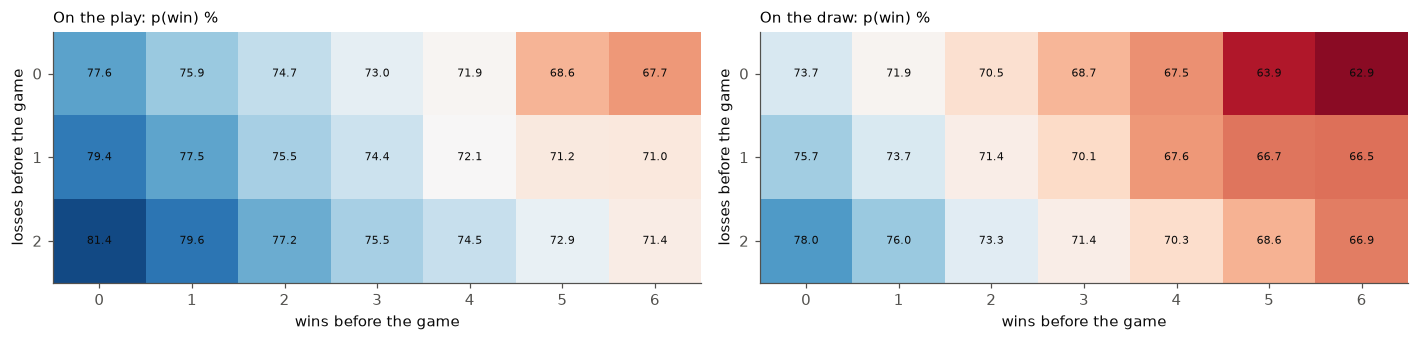

In [12]:
best = te_idx[np.argmax(deck_score[te_idx])]
deck_best = {names[j]: int(X[best, j]) for j in np.flatnonzero(X[best])}
grid_play = np.array([[predict_next(deck_best, w_, l_, True, "gold", "gold") for w_ in range(MAX_WINS)]
                      for l_ in range(MAX_LOSSES)])
grid_draw = np.array([[predict_next(deck_best, w_, l_, False, "gold", "gold") for w_ in range(MAX_WINS)]
                      for l_ in range(MAX_LOSSES)])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 3.2))
lo_, hi_ = min(grid_play.min(), grid_draw.min()) * 100 - 1, max(grid_play.max(), grid_draw.max()) * 100 + 1
heat(a1, grid_play * 100, None, "On the play: p(win) %", lambda v: f"{v:.1f}", "RdBu", lo_, hi_)
heat(a2, grid_draw * 100, None, "On the draw: p(win) %", lambda v: f"{v:.1f}", "RdBu", lo_, hi_)
plt.tight_layout(); plt.show()

## 9. Takeaways

1. **Model the next game, not the run.** One run in five changes its deck part-way through, and each game here uses
   the deck registered for it. The model takes the deck, the record so far, both ranks and play/draw, and returns a
   pre-game win probability (`predict_next`).
2. **The record matters, and it is matchmaking.** At a fixed deck and player, each win costs about 2 points of win
   probability and each loss gives back about 2.5. Better decks reaching high records hide this in the raw data.
   Adding the record improves held-out log loss by 0.0014, about a third of what the whole deck adds.
3. **League and skill.** The user's own rank is mostly about who they face (higher rank, lower win probability at a
   fixed deck). The 17Lands skill bucket is the strongest input but leaks the outcome; a live version should use
   win rate from earlier events only. Experience adds nothing on top of skill.
4. **Card power is stable, synergy is small.** Adding the record changes card weights by about 8% in scale and
   almost nothing in order. Pair synergy is about 40× smaller than card power and doesn't improve held-out games.
5. **Mulligans are the biggest in-game signal** (-0.63 log-odds per extra mulligan), but only for in-game or
   post-hoc models.
6. **Sealed** fits the same pipeline: the game file has the same deck and record columns, but no rank. There, the
   record, skill and draft-trained card weights (multi-task) will have to carry more of the load.